In [145]:
%pip install pandas numpy matplotlib seaborn scikit-learn joblib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [146]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    average_precision_score
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [147]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders available:")
print(os.listdir())

Current working directory:
c:\Users\Bharathi\OneDrive\Desktop\gradient-boosting-fraud-detection

Files and folders available:
['creditcard.csv', 'gradient_boosting_fraud_detection.ipynb']


In [148]:
# Load the dataset
df = pd.read_csv("creditcard.csv")

# Display the first five rows
df.head()

ParserError: Error tokenizing data. C error: Calling read(nbytes) on source failed. Try engine='python'.

In [ ]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (284807, 31)
Number of rows: 284807
Number of columns: 31


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [ ]:
# Check missing values in each column
print(df.isnull().sum())

# Check total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Total missing values: 0


In [ ]:
# Count legitimate and fraudulent transactions
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [ ]:
# Calculate transaction percentages
class_percentages = (
    df["Class"].value_counts(normalize=True) * 100
)

print(class_percentages.round(3))

Class
0    99.827
1     0.173
Name: proportion, dtype: float64


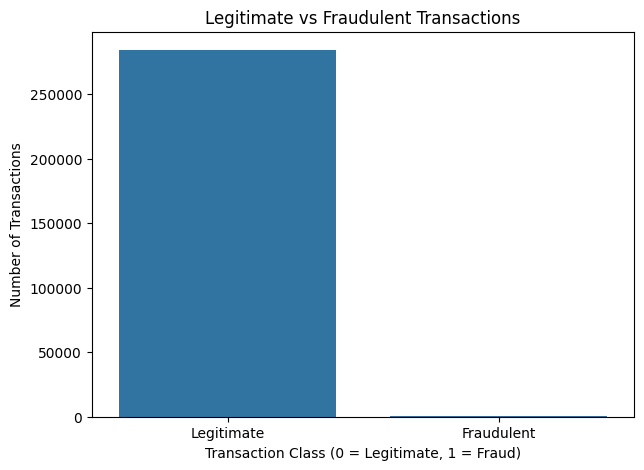

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

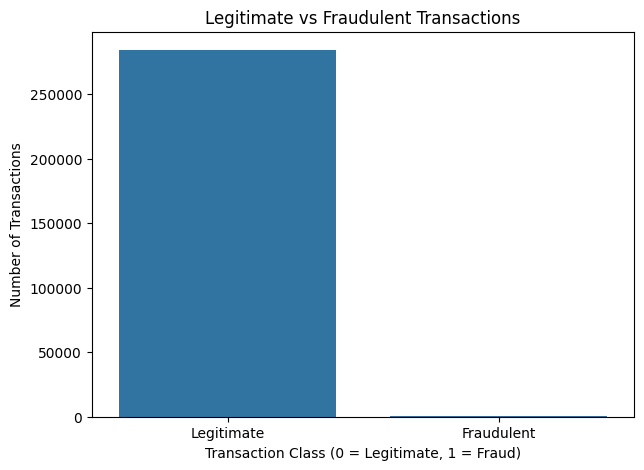

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class")

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Transaction Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])

plt.show()

In [ ]:
# Compare transaction amounts by class
print(
    df.groupby("Class")["Amount"].describe()
)

          count        mean         std  min   25%    50%     75%       max
Class                                                                      
0      284315.0   88.291022  250.105092  0.0  5.65  22.00   77.05  25691.16
1         492.0  122.211321  256.683288  0.0  1.00   9.25  105.89   2125.87


In [ ]:
# Check duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 1081


In [ ]:
# Create a cleaned copy without exact duplicate rows
df = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df.shape)
print("Duplicates remaining:", df.duplicated().sum())

Original dataset shape: (283726, 31)
Cleaned dataset shape: (283726, 31)
Duplicates remaining: 0


In [ ]:
# Count each transaction class
print(df["Class"].value_counts())

Class
0    283253
1       473
Name: count, dtype: int64


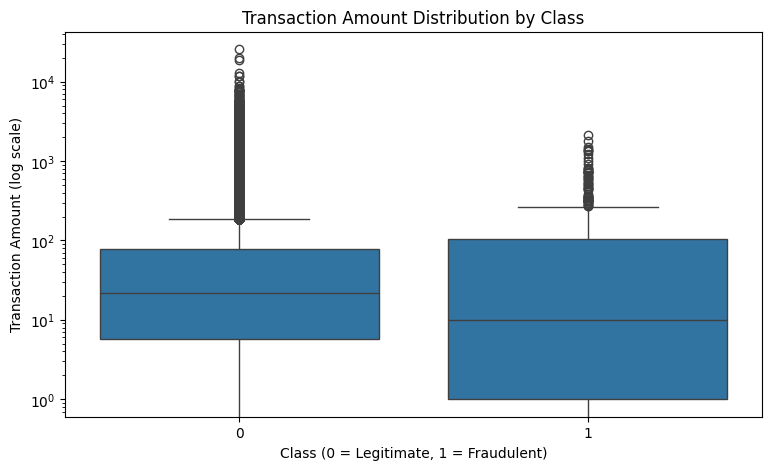

In [ ]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.yscale("log")
plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraudulent)")
plt.ylabel("Transaction Amount (log scale)")

plt.show()

In [ ]:
# Compare transaction time by class
print(
    df.groupby("Class")["Time"].describe()
)

          count          mean           std    min      25%      50%  \
Class                                                                  
0      283253.0  94835.058093  47475.550607    0.0  54233.0  84711.0   
1         473.0  80450.513742  48636.179973  406.0  41203.0  73408.0   

            75%       max  
Class                      
0      139308.0  172792.0  
1      129095.0  170348.0  


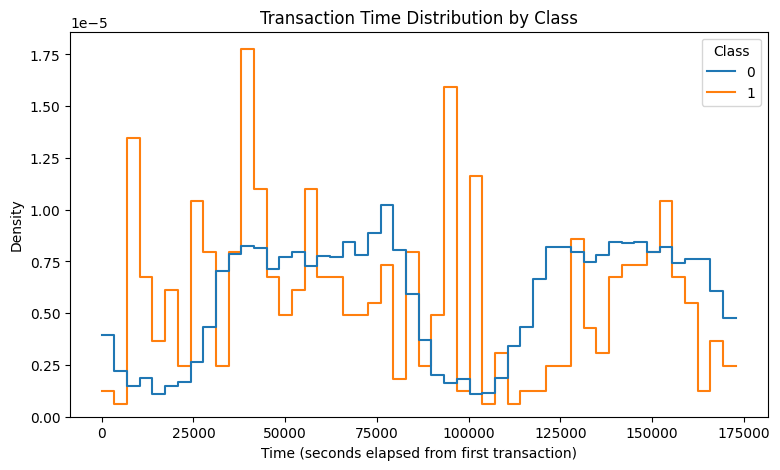

In [ ]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Time",
    hue="Class",
    bins=50,
    stat="density",
    common_norm=False,
    element="step",
    fill=False
)

plt.title("Transaction Time Distribution by Class")
plt.xlabel("Time (seconds elapsed from first transaction)")
plt.ylabel("Density")

plt.show()

In [ ]:
# Calculate correlations between numerical features
correlation_matrix = df.corr()

# Display correlations with the target variable
class_correlation = correlation_matrix["Class"].drop("Class")

print(
    class_correlation
    .sort_values(key=abs, ascending=False)
)

V17      -0.313498
V14      -0.293375
V12      -0.250711
V10      -0.206971
V16      -0.187186
V3       -0.182322
V7       -0.172347
V11       0.149067
V4        0.129326
V18      -0.105340
V1       -0.094486
V9       -0.094021
V5       -0.087812
V2        0.084624
V6       -0.043915
V19       0.033631
V8        0.033068
V21       0.026357
V27       0.021892
V20       0.021486
Time     -0.012359
V28       0.009682
V24      -0.007210
V23      -0.006333
Amount    0.005777
V22       0.004887
V26       0.004265
V13      -0.003897
V15      -0.003300
V25       0.003202
Name: Class, dtype: float64


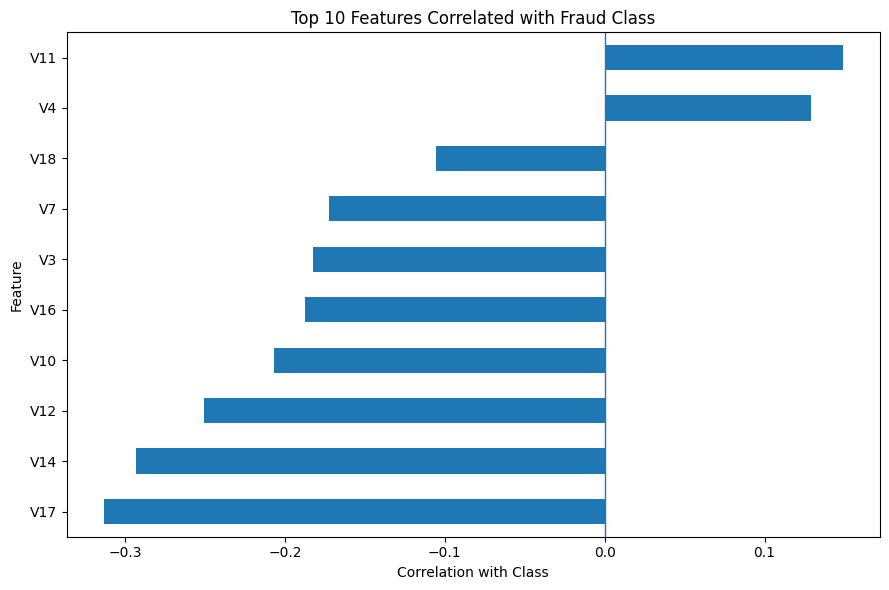

In [ ]:
# Select the 10 strongest correlations by absolute magnitude
top_correlations = (
    class_correlation
    .loc[class_correlation.abs().sort_values(ascending=False).head(10).index]
    .sort_values()
)

plt.figure(figsize=(9, 6))

top_correlations.plot(kind="barh")

plt.title("Top 10 Features Correlated with Fraud Class")
plt.xlabel("Correlation with Class")
plt.ylabel("Feature")
plt.axvline(0, linewidth=1)

plt.tight_layout()
plt.show()

In [ ]:
# Separate input features (X) and target (y)
X = df.drop("Class", axis=1)
y = df["Class"]

print("Feature matrix shape:", X.shape)
print("Target vector shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Feature matrix shape: (283726, 30)
Target vector shape: (283726,)

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [ ]:
# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training features: (226980, 30)
Testing features: (56746, 30)

Training target distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing target distribution:
Class
0    56651
1       95
Name: count, dtype: int64


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create a faster baseline model
gb_model = GradientBoostingClassifier(
    n_estimators=30,
    learning_rate=0.1,
    max_depth=2,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting model trained successfully!")

Gradient Boosting model trained successfully!


In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

# Create a fresh model
gb_model = GradientBoostingClassifier(
    n_estimators=10,
    learning_rate=0.1,
    max_depth=1,
    random_state=42
)

# Train the model
gb_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
y_pred = gb_model.predict(X_test)

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred))

Predictions generated successfully!
Number of predictions: 56746


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Model Evaluation Results")
print("------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

Model Evaluation Results
------------------------
Accuracy:  0.9990
Precision: 0.7317
Recall:    0.6316
F1-Score:  0.6780


Confusion Matrix:
[[56629    22]
 [   35    60]]


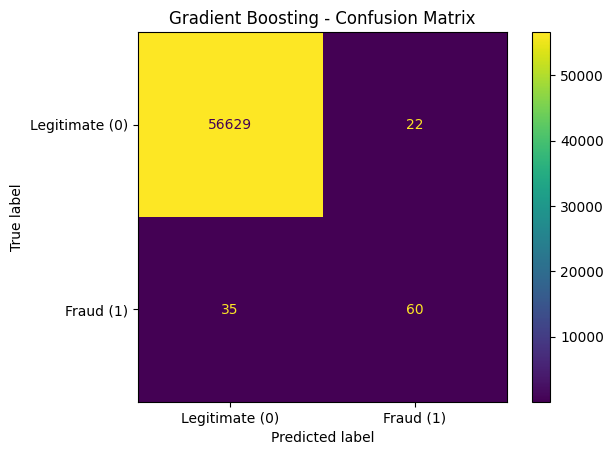

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate (0)", "Fraud (1)"]
)

display.plot()
plt.title("Gradient Boosting - Confusion Matrix")
plt.show()

In [ ]:
print("Classification Report")
print("---------------------")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Fraud"],
        digits=4
    )
)

Classification Report
---------------------
              precision    recall  f1-score   support

  Legitimate     0.9994    0.9996    0.9995     56651
       Fraud     0.7317    0.6316    0.6780        95

    accuracy                         0.9990     56746
   macro avg     0.8655    0.8156    0.8387     56746
weighted avg     0.9989    0.9990    0.9990     56746



In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier

hist_gb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.1,
    max_leaf_nodes=15,
    random_state=42
)

hist_gb_model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predict on test data
y_pred = hist_gb_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy:.4%}")

# Detailed evaluation
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 99.9066%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.71      0.75      0.73        95

    accuracy                           1.00     56746
   macro avg       0.85      0.87      0.86     56746
weighted avg       1.00      1.00      1.00     56746


Confusion Matrix:
[[56622    29]
 [   24    71]]


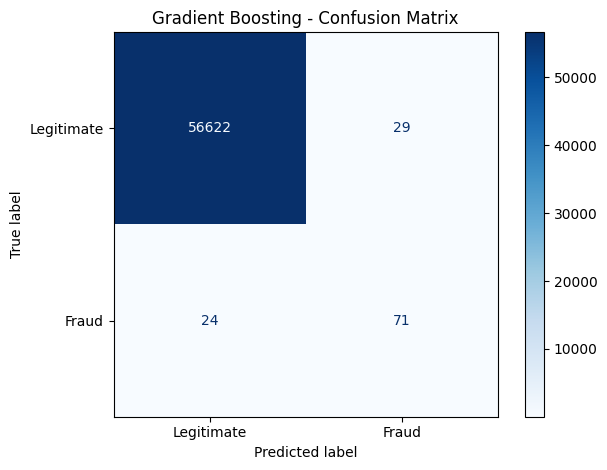

In [149]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Legitimate", "Fraud"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Gradient Boosting - Confusion Matrix")
plt.tight_layout()
plt.show()

Top 10 Important Features:
Feature  Importance
    V12    0.338891
    V14    0.332576
    V10    0.179131
    V17    0.166737
     V4    0.097590
    V26    0.062406
    V18    0.048477
     V1    0.020530
    V15    0.020380
   Time    0.014419


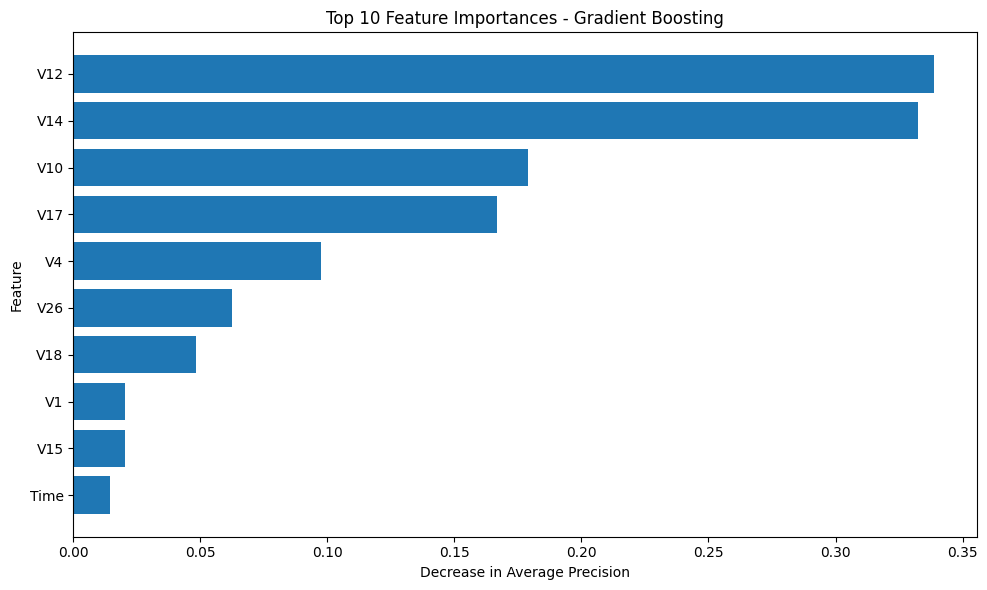

In [151]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score

# Calculate permutation importance
result = permutation_importance(
    hist_gb_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

# Get feature names
feature_names = (
    X_test.columns
    if hasattr(X_test, "columns")
    else [f"Feature_{i}" for i in range(X_test.shape[1])]
)

# Create importance table
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": result.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

print("Top 10 Important Features:")
print(feature_importance.head(10).to_string(index=False))

# Plot top 10 features
top_features = feature_importance.head(10).sort_values(
    by="Importance"
)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.title("Top 10 Feature Importances - Gradient Boosting")
plt.xlabel("Decrease in Average Precision")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


In [152]:
import joblib

# Save the trained model
joblib.dump(
    hist_gb_model,
    "gradient_boosting_fraud_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [153]:
import joblib

loaded_model = joblib.load(
    "gradient_boosting_fraud_model.pkl"
)

print("Saved model loaded successfully!")

Saved model loaded successfully!


In [154]:
# Select 5 transactions from the test dataset
sample_transactions = (
    X_test.iloc[:5]
    if hasattr(X_test, "iloc")
    else X_test[:5]
)

# Predict using the loaded model
predictions = loaded_model.predict(sample_transactions)

print("Predicted Labels:", predictions)
print("Actual Labels:", y_test[:5].tolist() if hasattr(y_test, "tolist") else y_test[:5])

Predicted Labels: [0 0 0 0 0]
Actual Labels: [0, 0, 0, 0, 0]
